# Прогнозирование вероятности закрытия сделки и приоритизация клиентов
## в системе корпоративных продаж НПФ (на примере проекта ПУЛЬС)

Выпускная квалификационная работа по курсу «Наука о данных: профессиональный уровень (Data Science PRO)», МГТУ им. Н.Э. Баумана.

Ноутбук воспроизводит весь исследовательский пайплайн: разведочный анализ данных, предобработку, инженерию признаков, обучение и сравнение моделей машинного обучения для двух задач — прогноза закрытия сделки и конверсии лида в сделку.

## 1. Постановка задачи

Данные — боевая выгрузка CRM Creatio проекта ПУЛЬС (снимок на 30.07.2026): 764 сделки (571 новая + 193 действующих клиента) и 399 лидов.

Ключевая методологическая особенность: целевая переменная для сделок точно известна только для **завершённых** записей (`is_terminal_success` или `is_terminal_failure`). Незавершённые сделки используются как inference-выборка, а не как обучающая, во избежание смешения меток «провал» и «ещё не решено».

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, confusion_matrix, classification_report

pd.set_option("display.width", 160)
plt.rcParams["font.size"] = 10
RANDOM_STATE = 42

## 2. Загрузка данных

Файлы очищены от персональных и идентифицирующих данных (наименование компании, ИНН, ФИО ответственного менеджера) до подачи в ноутбук.

In [2]:
deals_raw = pd.read_csv("сделки_v2.csv")
leads_raw = pd.read_csv("лиды_v2.csv")
print("Сделки:", deals_raw.shape)
print("Лиды:  ", leads_raw.shape)
deals_raw.head(3)

Сделки: (764, 27)
Лиды:   (399, 6)


,id,deal_kind,client_cohort,stage,is_terminal_success,is_terminal_failure,final_stage_at,potential_millions,payroll_millions,staff_count,...,industry,region,business_activity,holding_name,holding_excluded,decline_reason,objections_text,strategy,description,scoring_status
0,26,new_deal,new,Возражения,False,False,NaN,30.0,900.0,600,...,Перевозка грузов по внутренним водным путям,"163000, Архангельская обл., г.о. город Арханге...","Собственный флот, речные перевозки",НЕТ,False,NaN,NaN,"работаем только через банк ВТБ КИБ, при их уча...",NaN,active
1,27,new_deal,new,Сделка завершена с успехом,True,False,NaN,1.0,0.0,0,...,Деятельность по операциям с недвижимым имуществом,NaN,NaN,НЕТ,False,NaN,NaN,После переговоров с ФД направлен договор + пак...,NaN,excluded_completed
2,28,new_deal,new,Продажа,False,False,NaN,0.5,40.0,77,...,Разработка компьютерного программного обеспечения,"108811, г. Москва, вн.тер.г. муниципальный окр...",Разработка компьютерного программного обеспечения,НЕТ,False,NaN,NaN,направить клиенту презентацию программ по НПО ...,NaN,active


## 3. Разведочный анализ данных (EDA)

### 3.1 Сегментация и целевая переменная

In [3]:
df = deals_raw.copy()
df["is_existing_client"] = df["client_cohort"] == "existing"
df["is_resolved"] = df["is_terminal_success"] | df["is_terminal_failure"]

print("Новых сделок:", (~df["is_existing_client"]).sum())
print("Действующих клиентов:", df["is_existing_client"].sum())
print()
new = df[~df["is_existing_client"]]
print("Завершено (успех+провал):", new["is_resolved"].sum())
print("  из них успехов:", new["is_terminal_success"].sum())
print("  из них провалов:", new["is_terminal_failure"].sum())
print("Незавершено (inference-выборка):", (~new["is_resolved"]).sum())

Новых сделок: 571
Действующих клиентов: 193

Завершено (успех+провал): 274
  из них успехов: 7
  из них провалов: 267
Незавершено (inference-выборка): 297


### 3.2 Распределение по стадиям воронки

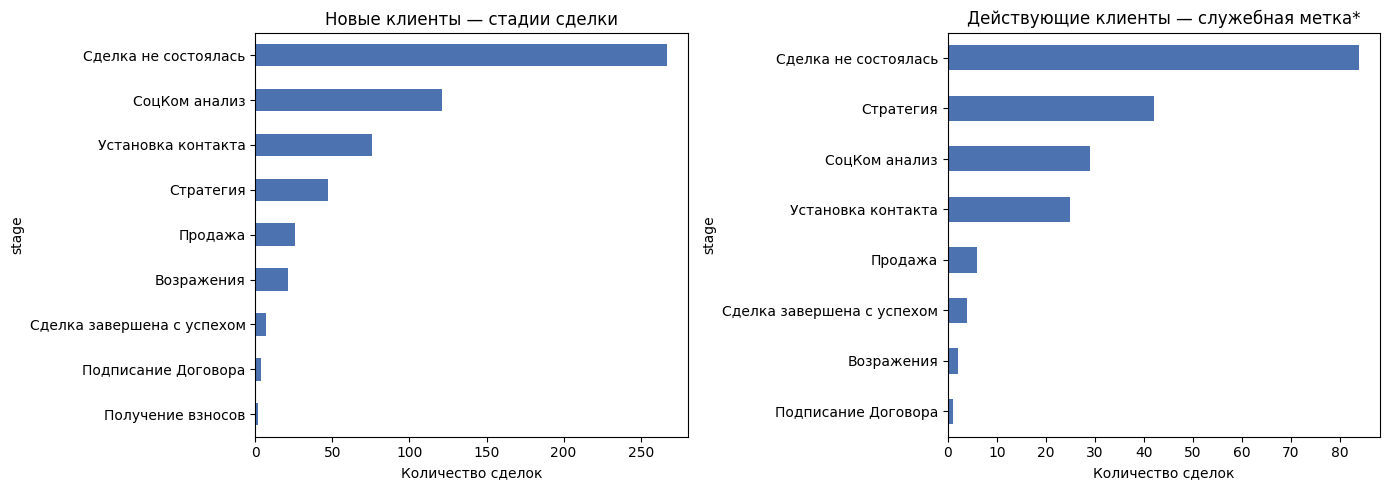

* У действующих клиентов 'Стадия' — служебная метка вовлечённости менеджера, а НЕ статус успеха сделки.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, flag, title in [
    (axes[0], False, "Новые клиенты — стадии сделки"),
    (axes[1], True, "Действующие клиенты — служебная метка*"),
]:
    counts = df[df["is_existing_client"] == flag]["stage"].value_counts()
    counts.plot(kind="barh", ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.invert_yaxis()
    ax.set_xlabel("Количество сделок")
plt.tight_layout()
plt.show()
print("* У действующих клиентов 'Стадия' — служебная метка вовлечённости менеджера, а НЕ статус успеха сделки.")

### 3.3 Распределения количественных признаков (потенциал, ФОТ)

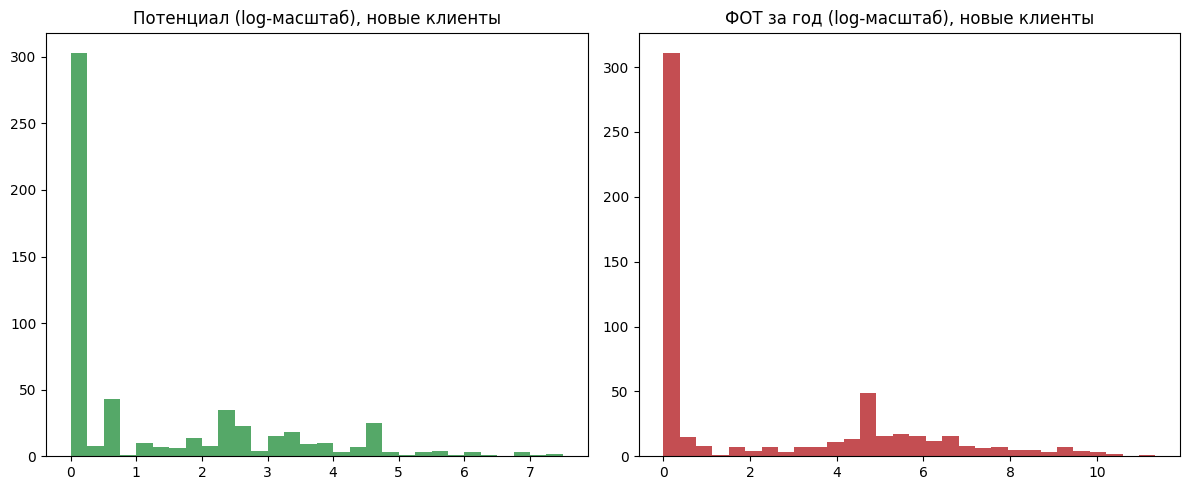

       potential_millions  payroll_millions    staff_count  days_since_last_contact
count          571.000000        571.000000     571.000000               571.000000
mean            31.984238        844.389317    1222.320490                65.124343
std            146.442373       4637.644194    8216.746883                55.244118
min              0.000000          0.000000       0.000000                 0.000000
25%              0.000000          0.000000       0.000000                16.000000
50%              0.000000          0.000000       2.000000                53.000000
75%             10.000000        111.000000     200.000000               122.000000
max           1808.000000      85000.000000  140000.000000               180.000000


In [5]:
new_df = df[~df["is_existing_client"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(np.log1p(new_df["potential_millions"].fillna(0)), bins=30, color="#55A868")
axes[0].set_title("Потенциал (log-масштаб), новые клиенты")
axes[1].hist(np.log1p(new_df["payroll_millions"].fillna(0)), bins=30, color="#C44E52")
axes[1].set_title("ФОТ за год (log-масштаб), новые клиенты")
plt.tight_layout()
plt.show()

print(new_df[["potential_millions", "payroll_millions", "staff_count", "days_since_last_contact"]].describe())

### 3.4 Проверка пропусков и качества полей

In [6]:
print("Пропуски по ключевым полям (новые сделки):")
print(new_df[["industry", "self_probability", "holding_name"]].isna().mean().round(3))
print()
print("Обозначения пустого 'holding_name' (требуют объединения):")
print(df["holding_name"].value_counts(dropna=False).head(6))

Пропуски по ключевым полям (новые сделки):
industry            0.270
self_probability    0.891
holding_name        0.053
dtype: float64

Обозначения пустого 'holding_name' (требуют объединения):
holding_name
НЕТ            498
РУСГИДРО        49
Отсутствует     48
РОССЕТИ         31
NaN             30
ОСК             14
Name: count, dtype: int64


## 4. Предобработка данных и инженерия признаков

- Объединение трёх обозначений отсутствия холдинга («НЕТ», «Отсутствует», пропуск) в одну категорию.
- Эвристика приоритизации `priority_score` (стадия → процент) — только для новых сделок.
- `weighted_potential` = потенциал × вероятность.
- `reactivation_score` — для провальных новых сделок, на основе реального поля `days_since_last_contact`, окно 365 дней.
- Для действующих клиентов эвристика НЕ считается — стадия у них не отражает статус сделки (см. главу 2 пояснительной записки).

In [7]:
holding_clean = df["holding_name"].fillna("НЕТ").replace({"Отсутствует": "НЕТ"})
df["is_holding_client"] = holding_clean != "НЕТ"

STAGE_HEURISTIC_PCT = {
    "Сделка не состоялась": 0, "СоцКом анализ": 5, "Установка контакта": 10,
    "Стратегия": 20, "Продажа": 35, "Возражения": 45,
    "Подписание Договора": 70, "Получение взносов": 90,
    "Сделка завершена с успехом": 100,
}
is_new = ~df["is_existing_client"]
df["priority_score"] = np.where(is_new, df["stage"].map(STAGE_HEURISTIC_PCT), np.nan)
df["priority_category"] = df["priority_score"].apply(
    lambda s: ("низкий" if s < 40 else "средний" if s <= 70 else "высокий") if pd.notna(s) else np.nan
)
df["weighted_potential"] = np.where(is_new, df["potential_millions"].fillna(0) * (df["priority_score"] / 100), np.nan)

is_failed_new = (df["stage"] == "Сделка не состоялась") & is_new
df["reactivation_score"] = np.nan
df.loc[is_failed_new, "reactivation_score"] = (
    np.clip(1 - df.loc[is_failed_new, "days_since_last_contact"] / 365, 0, 1) * 100
)

print(df.loc[is_new, "priority_category"].value_counts())

priority_category
низкий     537
средний     25
высокий      9
Name: count, dtype: int64


## 5. Сопоставление профилей успешных и неуспешных сделок

Действующие клиенты (кроме источника «Холдинг», исключённого на уровне выгрузки) рассматриваются как исторически успешные — независимо от текущей стадии (см. главу 2 пояснительной записки).

In [8]:
new_success = df[is_new & df["is_terminal_success"]]
new_failed = df[is_new & df["is_terminal_failure"]]
existing = df[df["is_existing_client"]]

profile = pd.DataFrame({
    "Новые, успех": [len(new_success), new_success["staff_count"].median(), new_success["is_holding_client"].mean()],
    "Новые, провал": [len(new_failed), new_failed["staff_count"].median(), new_failed["is_holding_client"].mean()],
    "Действующие": [len(existing), existing["staff_count"].median(), existing["is_holding_client"].mean()],
}, index=["n", "Штат (медиана)", "Доля с холдингом"])
profile

,"Новые, успех","Новые, провал",Действующие
n,7.000000,267.000000,193.000000
Штат (медиана),30.000000,1.000000,160.000000
Доля с холдингом,0.428571,0.108614,0.559585


## 6. Модель 1: прогнозирование вероятности закрытия сделки

Обучение только на 274 завершённых новых сделках. Стадия и производные от неё показатели исключены из признаков — иначе целевая переменная «подсматривается» через стадию. Кросс-валидация — StratifiedKFold, 5 блоков (при 7 позитивах стандартные 10 блоков дали бы блоки без единого положительного примера).

In [9]:
resolved = df[is_new & df["is_resolved"]].copy()
unresolved = df[is_new & ~df["is_resolved"]].copy()
y = resolved["is_terminal_success"].astype(int).reset_index(drop=True)

def build_features(frame):
    f = frame.copy()
    f["log_potential"] = np.log1p(f["potential_millions"].fillna(0))
    f["log_payroll"] = np.log1p(f["payroll_millions"].fillna(0))
    f["staff_count"] = f["staff_count"].fillna(0)
    f["days_since_last_contact"] = f["days_since_last_contact"].fillna(f["days_since_last_contact"].median())
    return f

train_f = build_features(resolved)
infer_f = build_features(unresolved)
combined = pd.concat([train_f, infer_f], ignore_index=True)
source_dummies = pd.get_dummies(combined["source"], prefix="source", drop_first=True)
industry_dummies = pd.get_dummies(combined["industry"].fillna("Не указано"), prefix="ind", drop_first=True)
numeric_cols = ["log_potential", "log_payroll", "staff_count", "presentation_exists",
                 "spin_exists", "days_since_last_contact", "is_holding_client"]
X_all = pd.concat([combined[numeric_cols].reset_index(drop=True),
                    source_dummies.reset_index(drop=True),
                    industry_dummies.reset_index(drop=True)], axis=1).fillna(0)
X_train = X_all.iloc[:len(train_f)].reset_index(drop=True)
X_infer = X_all.iloc[len(train_f):].reset_index(drop=True)
print("Признаков:", X_train.shape[1], "| строк обучения:", len(X_train), "| inference:", len(X_infer))

Признаков: 60 | строк обучения: 274 | inference: 297


In [10]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X_train, y))

oof = {}
oof["Логрег"] = np.zeros(len(y))
oof["Random Forest"] = np.zeros(len(y))
oof["Gradient Boosting"] = np.zeros(len(y))

for tr, te in folds:
    m = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
    m.fit(X_train.iloc[tr], y.iloc[tr]); oof["Логрег"][te] = m.predict_proba(X_train.iloc[te])[:, 1]

    m = RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=5,
                                 class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train.iloc[tr], y.iloc[tr]); oof["Random Forest"][te] = m.predict_proba(X_train.iloc[te])[:, 1]

    m = HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.05,
                                          class_weight="balanced", random_state=RANDOM_STATE)
    m.fit(X_train.iloc[tr], y.iloc[tr]); oof["Gradient Boosting"][te] = m.predict_proba(X_train.iloc[te])[:, 1]

print("Обучение завершено")

Обучение завершено


### 6.1 Сравнение моделей

In [11]:
heuristic_proba = (resolved["priority_score"].reset_index(drop=True) / 100).values
puls_proba = (resolved["probability"].fillna(0).reset_index(drop=True) / 100).values

def best_f1(y_true, proba):
    ts = np.linspace(0.01, 0.99, 99)
    scores = [f1_score(y_true, proba >= t) for t in ts]
    i = int(np.argmax(scores))
    return scores[i], ts[i]

positives_idx = y[y == 1].index
rows = []
for name, proba in {**oof, "Эвристика (стадия)": heuristic_proba, "Системная probability ПУЛЬС": puls_proba}.items():
    roc = roc_auc_score(y, proba)
    pr = average_precision_score(y, proba)
    f1, t = best_f1(y, proba)
    rank = pd.Series(proba).rank(ascending=False)
    top30 = int((rank.loc[positives_idx] <= 30).sum())
    rows.append({"Модель": name, "ROC-AUC": round(roc,3), "PR-AUC": round(pr,3),
                 "Лучший F1": round(f1,3), "Успехов в топ-30": f"{top30}/7"})
comparison = pd.DataFrame(rows).set_index("Модель")
comparison

,ROC-AUC,PR-AUC,Лучший F1,Успехов в топ-30
Модель,,,,
Логрег,0.777,0.337,0.500,3/7
Random Forest,0.781,0.125,0.214,3/7
Gradient Boosting,0.854,0.156,0.303,5/7
Эвристика (стадия),1.000,1.000,1.000,7/7
Системная probability ПУЛЬС,1.000,1.000,1.000,7/7


**Вывод:** Gradient Boosting показывает наилучший результат по практической метрике (успехов в топ-30). Эвристика и системная вероятность ПУЛЬС дают ROC-AUC = 1,0 не за счёт превосходства, а потому что используют стадию сделки, эквивалентную целевой переменной для завершённых сделок (подробное обоснование — глава 3, п. 3.3 пояснительной записки).

### 6.2 Важность признаков (Random Forest)

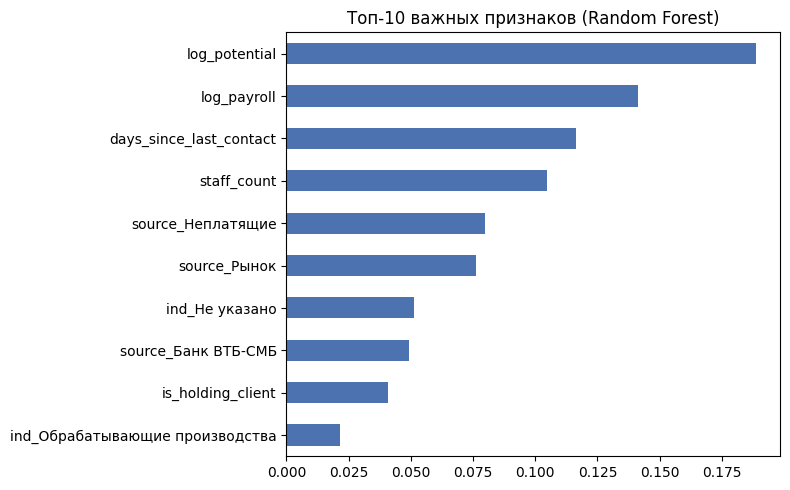

In [12]:
final_rf = RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=5,
                                    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
final_rf.fit(X_train, y)
importances = pd.Series(final_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importances.head(10).sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Топ-10 важных признаков (Random Forest)")
plt.tight_layout()
plt.show()

### 6.3 Инференс: прогноз для незавершённых сделок

In [13]:
final_gbm = HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.05,
                                              class_weight="balanced", random_state=RANDOM_STATE)
final_gbm.fit(X_train, y)
unresolved = unresolved.copy()
unresolved["ml_proba"] = final_gbm.predict_proba(X_infer)[:, 1]

top_active = unresolved.sort_values("ml_proba", ascending=False).head(15)
top_active[["id", "stage", "potential_millions", "ml_proba"]]

,id,stage,potential_millions,ml_proba
259,1080,Стратегия,3.0,0.980875
505,1329,СоцКом анализ,2.0,0.979631
24,50,Получение взносов,1.0,0.979525
269,1091,Стратегия,2.0,0.951320
14,40,Продажа,3.0,0.947047
264,1086,Продажа,2.0,0.921136
254,1075,Продажа,4.0,0.907490
265,1087,Стратегия,2.0,0.907490
286,1108,Установка контакта,1.0,0.808553
670,1498,Стратегия,13.0,0.771875


## 7. Модель 2: конверсия лида в сделку

Аналогичный принцип: обучение только на решённых лидах («Нецелевой» / «Переведён в сделку»), лиды со статусом «Целевой»/«Необработан» — inference-выборка. Источники, связанные с действующими клиентами (Холдинг/Платящие/Неплатящие), исключены.

In [14]:
leads = leads_raw.copy()
leads["created_at"] = pd.to_datetime(leads["created_at"])
leads["status_changed_at"] = pd.to_datetime(leads["status_changed_at"])

EXISTING_SOURCES = {"Холдинг", "Платящие", "Неплатящие"}
leads_new = leads[~leads["source"].isin(EXISTING_SOURCES)].copy()
leads_new["is_resolved"] = leads_new["lead_status"].isin(["Нецелевой", "Переведён в сделку"])
leads_new["target"] = (leads_new["lead_status"] == "Переведён в сделку").astype(int)

resolved_l = leads_new[leads_new["is_resolved"]].copy()
unresolved_l = leads_new[~leads_new["is_resolved"]].copy()
print("Решённых лидов:", len(resolved_l), "| конверсий:", resolved_l["target"].sum())
print("Нерешённых (inference):", len(unresolved_l))

snapshot = leads_new["status_changed_at"].max()
for frame in (resolved_l, unresolved_l):
    frame["days_since_created"] = (snapshot - frame["created_at"]).dt.days

combined_l = pd.concat([resolved_l, unresolved_l], ignore_index=True)
source_dummies_l = pd.get_dummies(combined_l["source"], prefix="source", drop_first=True)
X_all_l = pd.concat([combined_l[["days_since_created"]].reset_index(drop=True),
                      source_dummies_l.reset_index(drop=True)], axis=1)
X_train_l = X_all_l.iloc[:len(resolved_l)].reset_index(drop=True)
X_infer_l = X_all_l.iloc[len(resolved_l):].reset_index(drop=True)
y_l = resolved_l["target"].reset_index(drop=True)

Решённых лидов: 285 | конверсий: 104
Нерешённых (inference): 100


In [15]:
skf_l = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds_l = list(skf_l.split(X_train_l, y_l))
oof_l = {}
for name, Cls, kwargs in [
    ("Логрег", LogisticRegression, dict(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    ("Random Forest", RandomForestClassifier, dict(n_estimators=300, max_depth=4, min_samples_leaf=5,
                                                     class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    ("Gradient Boosting", HistGradientBoostingClassifier, dict(max_depth=3, max_iter=150, learning_rate=0.05,
                                                                  class_weight="balanced", random_state=RANDOM_STATE)),
]:
    oof_p = np.zeros(len(y_l))
    for tr, te in folds_l:
        m = Cls(**kwargs)
        m.fit(X_train_l.iloc[tr], y_l.iloc[tr])
        oof_p[te] = m.predict_proba(X_train_l.iloc[te])[:, 1]
    oof_l[name] = oof_p

rows = []
for name, proba in oof_l.items():
    roc = roc_auc_score(y_l, proba)
    pr = average_precision_score(y_l, proba)
    f1, t = best_f1(y_l, proba)
    rows.append({"Модель": name, "ROC-AUC": round(roc,3), "PR-AUC": round(pr,3), "Лучший F1": round(f1,3)})
pd.DataFrame(rows).set_index("Модель")

,ROC-AUC,PR-AUC,Лучший F1
Модель,,,
Логрег,0.719,0.682,0.626
Random Forest,0.714,0.671,0.637
Gradient Boosting,0.694,0.585,0.615


In [16]:
final_lead_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
final_lead_model.fit(X_train_l, y_l)
unresolved_l = unresolved_l.copy()
unresolved_l["conversion_proba"] = final_lead_model.predict_proba(X_infer_l)[:, 1]

top_leads = unresolved_l.sort_values("conversion_proba", ascending=False).head(15)
top_leads[["id", "lead_status", "source", "days_since_created", "conversion_proba"]]

,id,lead_status,source,days_since_created,conversion_proba
328,1921,Целевой,Банк ВТБ-СМБ,106,0.889886
152,1745,Целевой,Банк ВТБ-СМБ,78,0.871310
151,1744,Целевой,Банк ВТБ-СМБ,73,0.867725
369,1962,Целевой,Банк ВТБ-КИБ,114,0.863435
370,1963,Целевой,Банк ВТБ-КИБ,114,0.863435
73,1666,Целевой,Банк ВТБ-СМБ,38,0.840206
112,1705,Целевой,Банк ВТБ-КИБ,53,0.811311
109,1702,Целевой,Банк ВТБ-КИБ,50,0.808391
32,1625,Целевой,Банк ВТБ-КИБ,18,0.775098
196,1789,Целевой,Корп страница Фонда,100,0.750318


## 8. Выводы

1. Прогнозирование вероятности закрытия сделки и приоритизация клиентов реализованы на реальных данных проекта ПУЛЬС.
2. Ключевое методологическое решение — обучение только на завершённых сделках (274 из 571 новых) — устраняет смешение меток «провал» и «ещё не решено».
3. **Gradient Boosting** — лучшая модель по практической метрике (успехов в топ-30), при этом **Random Forest** обеспечивает наиболее устойчивую и интерпретируемую оценку важности признаков.
4. Признаки масштаба клиента (штат, холдинг) — устойчивый предиктор успеха, подтверждённый как на 7 успешных новых сделках, так и на 193 действующих клиентах.
5. Вторая модель (конверсия лида в сделку) построена по тому же методологическому принципу и достигает ROC-AUC ≈ 0,72.
6. Обе модели применены к незавершённым записям (сделки и лиды) — практический результат в виде приоритизированных списков, не только оценка на исторических данных.

Подробное обсуждение результатов, архитектуры программного сервиса и практической значимости — см. пояснительную записку, главы 2-3.